<a href="https://colab.research.google.com/github/scottdzimmerman/GOGET/blob/main/Distance_to_Shore_2026_03_04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# load in libraries and data
# mount google drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#import libaries
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import datetime
from shapely.ops import nearest_points
import geopy.distance



In [ ]:
# import data
# GOGET
GOGET_Folder = '/content/drive/Shareddrives/GEM Shared Drive/Programs/Oil & Gas Program/Global Oil and Gas Extraction Tracker (GOGET)/'
# GOGET_Data = GOGET_Folder + 'GOGET Iterations/Official Releases of GOGET/Global-Oil-and-Gas-Extraction-Tracker-March-2026.xlsx'
GOGET_iterations_folder = GOGET_Folder + 'GOGET Iterations/Snapshots of GOGET main data set/'
GOGET_File_Name = 'all-offshore-fields-2026-03-06T215925.csv'
GOGET_Data = GOGET_iterations_folder + GOGET_File_Name

# Natural Earth
NECoast = GOGET_Folder + 'Reports/Q1 2025 GOGET Report/GOGET Maps Files/Natural_Earth_quick_start/10m_physical/' + 'ne_10m_coastline.shp'

In [ ]:
# load in goget_data to a df, sheet = main data
# goget_data = pd.read_excel(GOGET_Data, sheet_name = 'Field-level main data') # for when pulling from data download
goget_data = pd.read_csv(GOGET_Data) # pull from GOGET direct download

In [ ]:
#filter data

# Filter the DataFrame for offshore
filtered_goget_data = goget_data[
    (goget_data['Onshore/Offshore'] == 'offshore')
]
# set parameter based on Unit ID - missing due to faulty "offshore" tag
Unit_id_List = ('L100000322944', 'L100000322894', 'L100000322892', 'L100000322877', 'L100000316123','L100000315393')

# filter for Unit ID in unit ID list
# filtered_goget_data = goget_data[goget_data['Unit ID'].isin(Unit_id_List)]

In [ ]:
# Create a GeoDataFrame
geometry = gpd.points_from_xy(filtered_goget_data.Longitude, filtered_goget_data.Latitude)
GOGET_geo_df = gpd.GeoDataFrame(filtered_goget_data, geometry=geometry)

# Set the CRS (Coordinate Reference System) - typically WGS 84 for lat/lon
GOGET_geo_df.crs = "EPSG:4326"

# Display the first few rows of the GeoDataFrame to verify
GOGET_geo_df.head()


,Unit Type,Project/Complex,Concession/Block,Basin,Unit ID,Unit Name,Base Name,Unit local script,Other Names,Fuel type,...,Concessionblock Data Source,Basin Data Source,Operators Data Source,Owners Data Source,Location Data Source,Status Data Source,Discovery Year Data Source,Fid Year Data Source,Production Start Year Data Source,geometry
0,field,NaN,NaN,NaN,L100000318123,16/1-34 S (Lillefix) Oil and Gas Field (Norway),16/1-34 S (Lillefix),NaN,NaN,oil and gas,...,NaN,NaN,https://factpages.npd.no/factpages/default.asp...,https://factpages.npd.no/en/discovery/pageview...,https://factpages.npd.no/en/discovery/pageview...,https://factpages.npd.no/factpages/default.asp...,https://factpages.npd.no/en/discovery/pageview...,NaN,NaN,POINT (2.3301 58.9845)
1,field,Solveig Oil and Gas Project (Norway),PL359,NaN,L100000313899,16/4-13 S Oil and Gas Field (Norway),16/4-13 S,NaN,NaN,oil and gas,...,https://www.ogj.com/exploration-development/di...,NaN,https://factpages.sodir.no/en/discovery/pagevi...,NaN,https://factmaps.sodir.no/api/rest/services/Fa...,https://factpages.sodir.no/en/discovery/TableV...,https://www.ogj.com/exploration-development/di...,NaN,NaN,POINT (2.1843 58.7168)
2,project,NaN,2008 PSC,NaN,L100001064711,2008 PSC Oil and Gas Project (Malaysia),2008 PSC,NaN,1995 PSC,oil and gas,...,https://theedgemalaysia.com/article/exxonmobil...,NaN,https://www.linkedin.com/pulse/malaysia-non-ma...,https://www.linkedin.com/pulse/malaysia-non-ma...,NaN,https://www.linkedin.com/pulse/malaysia-non-ma...,NaN,NaN,NaN,POINT (NaN NaN)
3,field,NaN,NaN,NaN,L100000318126,24/12-7 (Lyderhorn) Oil and Gas Field (Norway),24/12-7 (Lyderhorn),NaN,NaN,oil and gas,...,NaN,NaN,https://factpages.npd.no/en/licence/pageview/a...,https://factpages.npd.no/en/discovery/pageview...,https://factpages.npd.no/en/discovery/pageview...,https://factpages.npd.no/factpages/default.asp...,https://factpages.npd.no/factpages/default.asp...,NaN,NaN,POINT (1.8192 59.1902)
4,field,NaN,NaN,NaN,L100000320775,25/7-11 S (Norma) Oil and Gas Field (Norway),25/7-11 S (Norma),NaN,NaN,oil and gas,...,NaN,NaN,https://factpages.sodir.no/downloads/shape/dsc...,NaN,https://factpages.sodir.no/en/discovery/pagevi...,https://factpages.sodir.no/en/discovery/TableV...,https://factpages.sodir.no/en/discovery/TableV...,NaN,NaN,POINT (2.0758 59.2927)


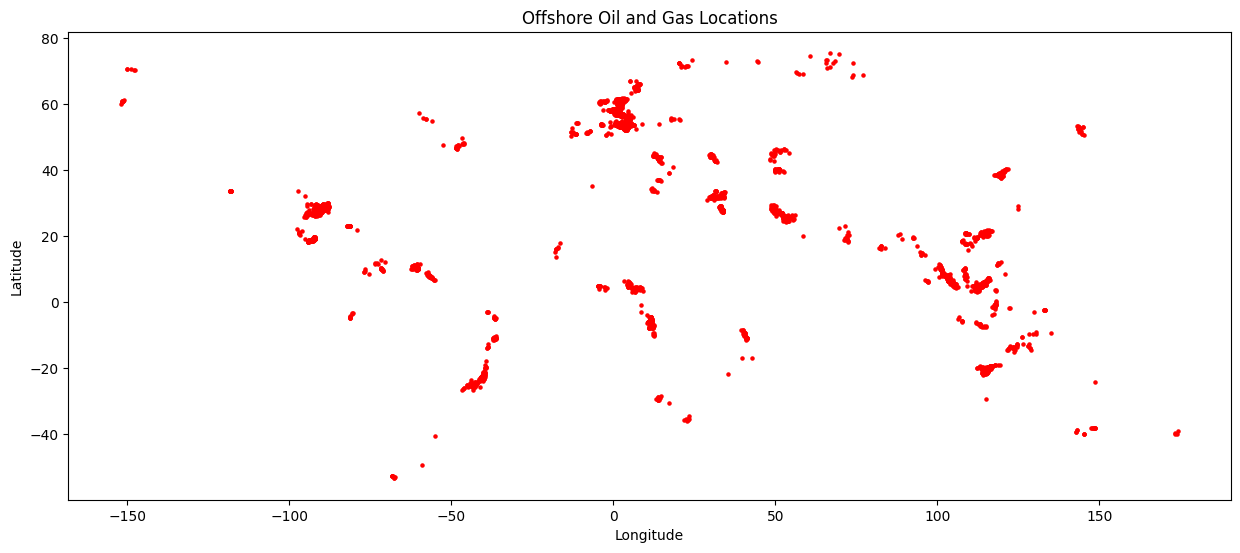

In [ ]:
# Plot the GOGET_geo_df to ensure it loaded properly
fig, ax = plt.subplots(figsize=(15, 10))
GOGET_geo_df.plot(ax=ax, marker='o', color='red', markersize=5)
ax.set_title('Offshore Oil and Gas Locations')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.show()


  featurecla  scalerank  min_zoom  \
0  Coastline          0       0.0   
1  Coastline          0       0.0   
2  Coastline          6       5.0   
3  Coastline          0       0.0   
4  Coastline          0       0.0   

                                            geometry  
0  LINESTRING (59.91603 -67.40049, 59.67856 -67.3...  
1  LINESTRING (-51.73062 -82.0626, -52.18688 -82....  
2  LINESTRING (166.13697 -50.86435, 166.10711 -50...  
3  LINESTRING (-56.66832 -36.73642, -56.66487 -36...  
4  LINESTRING (-51.07939 3.49209, -51.09648 3.449...  


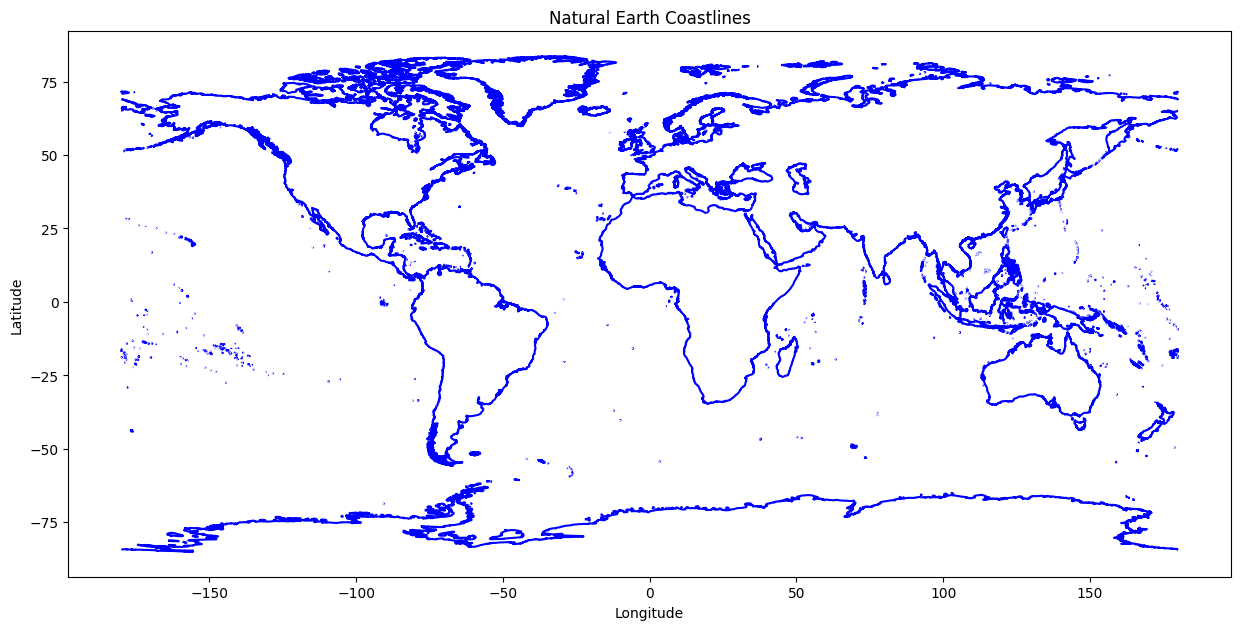

In [ ]:
# Load the Natural Earth coastlines shapefile into a GeoDataFrame
NECoast_gdf = gpd.read_file(NECoast)

# Set the CRS (Coordinate Reference System) - typically WGS 84 for lat/lon
NECoast_gdf.crs = "EPSG:4326"

# Display the first few rows of the GeoDataFrame to verify
print(NECoast_gdf.head())

# Plot the NECoast_gdf to ensure it loaded properly
fig, ax = plt.subplots(figsize=(15, 10))
NECoast_gdf.plot(ax=ax, color='blue')
ax.set_title('Natural Earth Coastlines')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.show()


In [ ]:
# Ensure both GeoDataFrames are in the same CRS
GOGET_geo_df = GOGET_geo_df.to_crs(NECoast_gdf.crs)

# Filter out rows with NaN in Latitude or Longitude before calculations
GOGET_geo_df = GOGET_geo_df.dropna(subset=['Latitude', 'Longitude'])

# combine coastline into single object using union_all() as recommended
coastline_raw = NECoast_gdf.geometry.union_all()
# Simplify the coastline to reduce complexity
# A tolerance of 0.01 degrees is roughly 1 km at the equator, which should be sufficient
# to simplify without losing significant detail for this type of calculation.
coastline = coastline_raw.simplify(tolerance=0.01, preserve_topology=True)

# Attempt to fix any invalid geometries using buffer(0)
# This is a common workaround for GEOSExceptions when dealing with complex geometries
if not coastline.is_valid:
    print("Coastline geometry is not valid. Attempting to fix with buffer(0).")
    coastline = coastline.buffer(0)
    if not coastline.is_valid:
        print("Coastline geometry is still not valid after buffer(0).")


# Function to calculate the distance to the nearest coastline in kilometers
def distance_to_coast(point):
    try:
        # Ensure the point itself is valid before proceeding
        if point.is_empty or not point.is_valid:
            raise ValueError("Invalid or empty point geometry.")

        nearest_geom = nearest_points(point, coastline)[1]
        # Convert point and nearest_geom to lat/lon tuples
        point_coords = (point.y, point.x)  # Latitude, Longitude
        nearest_coords = (nearest_geom.y, nearest_geom.x)  # Latitude, Longitude
        # Calculate distance using geopy.distance
        distance_km = geopy.distance.distance(point_coords, nearest_coords).km
        return distance_km
    except Exception as e:
        # Catching a general Exception to cover any potential shapely/GEOS error
        # In a production environment, one might want to be more specific (e.g., GEOSException)
        print(f"Could not calculate distance for point {point}. Error: {e}. Returning NaN.")
        return np.nan

# Calculate the distance for each point in GOGET_geo_df
GOGET_geo_df['distance_to_coast_km'] = GOGET_geo_df['geometry'].apply(distance_to_coast)

# sort by distance, high to low, correcting column name
GOGET_geo_df = GOGET_geo_df.sort_values(by='distance_to_coast_km', ascending=False)

# Display the updated GOGET_geo_df with distance information
print(GOGET_geo_df[['Unit Name','geometry', 'Discovery year', 'distance_to_coast_km']].head())

                                              Unit Name  \
2853         Shtokman Gas and Condensate Field (Russia)   
2538  Persephone Oil Asset (Newfoundland & Labrador,...   
256   Baccalieu Oil and Gas Field (Newfoundland & La...   
1282  Harpoon Oil and Gas Field (Newfoundland & Labr...   
2147  Mizzen Oil and Gas Field (Newfoundland & Labra...   

                      geometry  Discovery year  distance_to_coast_km  
2853   POINT (44.4964 73.0004)          1988.0            496.088154  
2538  POINT (-46.7212 49.7177)             NaN            493.115847  
256   POINT (-46.1989 48.0082)          2016.0            483.965889  
1282  POINT (-46.2136 48.0787)          2013.0            483.486983  
2147  POINT (-46.2903 48.2426)          2010.0            479.750550  


In [ ]:
# set distance threshholds per Hanna's research (https://app.asana.com/1/1200305284526705/task/1213032979159960?focus=true)
US_threshold = 5.556
Argentina_threshold = 22.224
Australia_threshold = 5.556
Colombia_threshold = 0
India_threshold = 0
Peru_threshold = 0
Mexico_threshold = 0
other_threshold = 0

# todo add texas and florida threshold is 9 nm.
country_thresholds = {
    'United States': US_threshold,
    'Argentina': Argentina_threshold,
    'Australia': Australia_threshold,
    'Colombia': Colombia_threshold,
    'India': India_threshold,
    'Peru': Peru_threshold,
    'Mexico': Mexico_threshold,
    'Other': other_threshold
}

print(country_thresholds)

{'United States': 5.556, 'Argentina': 22.224, 'Australia': 5.556, 'Colombia': 0, 'India': 0, 'Peru': 0, 'Mexico': 0, 'Other': 0}


In [ ]:
def check_distance_exceeds_threshold(row):
    country = row['Country/Area']  # Assuming 'Country' column exists in GOGET_geo_df
    distance = row['distance_to_coast_km']

    # Get the threshold for the country, or use 'Other' as default
    threshold = country_thresholds.get(country, country_thresholds['Other'])

    return distance > threshold

# Apply the function to create the new column
GOGET_geo_df['distance_exceeds_threshold'] = GOGET_geo_df.apply(check_distance_exceeds_threshold, axis=1)

# Display the first few rows with the new column
print(GOGET_geo_df[['Unit Name', 'Country/Area', 'distance_to_coast_km', 'distance_exceeds_threshold']].head())

                                              Unit Name Country/Area  \
2853         Shtokman Gas and Condensate Field (Russia)       Russia   
2538  Persephone Oil Asset (Newfoundland & Labrador,...       Canada   
256   Baccalieu Oil and Gas Field (Newfoundland & La...       Canada   
1282  Harpoon Oil and Gas Field (Newfoundland & Labr...       Canada   
2147  Mizzen Oil and Gas Field (Newfoundland & Labra...       Canada   

      distance_to_coast_km  distance_exceeds_threshold  
2853            496.088154                        True  
2538            493.115847                        True  
256             483.965889                        True  
1282            483.486983                        True  
2147            479.750550                        True  


In [ ]:
# create timestamp
timestamp = datetime.datetime.now().strftime("%Y-%m-%d_%H-%M-%S")

In [ ]:
# save GOGET_geo_df
file_name = f'distance_to_shore_{timestamp}'
outputfolder = '/content/drive/Shareddrives/GEM Shared Drive/Programs/Oil & Gas Program/Global Oil and Gas Extraction Tracker (GOGET)/QC/QC Output Dump/'
GOGET_geo_df.to_csv(outputfolder + file_name + '.csv')

# print location
print(f'file saved as: ' + file_name + ' in the folder named: ' + outputfolder)

file saved as: distance_to_shore_2026-03-06_22-10-20 in the folder named: /content/drive/Shareddrives/GEM Shared Drive/Programs/Oil & Gas Program/Global Oil and Gas Extraction Tracker (GOGET)/QC/QC Output Dump/


In [ ]:
# count values in distance_exceeds_threshold
GOGET_geo_df['distance_exceeds_threshold'].value_counts()

,count
distance_exceeds_threshold,
True,3191
False,46
